In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
DATA_PATH = "seeds_data.csv"
TARGET_COL = "Class"


In [2]:
df = pd.read_csv(DATA_PATH)
display(df.head())
print("Dataset shape:", df.shape)
print("Missing values:\n", df.isna().sum())

if TARGET_COL not in df.columns:
    raise ValueError(f"Expected target column {TARGET_COL!r}; found {df.columns.tolist()}")
if df.isna().any().any():
    raise ValueError("Please handle missing values before clustering.")

y_true = df[TARGET_COL].to_numpy()       
feature_names = df.drop(columns=[TARGET_COL]).columns.tolist()
X_raw = df[feature_names].to_numpy(dtype=float)

# Standardize each feature manually (no sklearn).
feature_mean = X_raw.mean(axis=0)
feature_std = X_raw.std(axis=0)
feature_std[feature_std == 0] = 1.0
X = (X_raw - feature_mean) / feature_std

print("Samples:", X.shape[0], "| features:", X.shape[1])
print("Classes (evaluation only):", np.unique(y_true))


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


Dataset shape: (210, 8)
Missing values:
 Feature_1    0
Feature_2    0
Feature_3    0
Feature_4    0
Feature_5    0
Feature_6    0
Feature_7    0
Class        0
dtype: int64
Samples: 210 | features: 7
Classes (evaluation only): [1 2 3]


In [3]:
def kmeans(X, k=3, max_iter=300, tol=1e-5, n_init=30, random_state=42):
    X = np.asarray(X, dtype=float)
    rng = np.random.default_rng(random_state)
    best = None

    for _ in range(n_init):
        centers = X[rng.choice(len(X), size=k, replace=False)].copy()

        for iteration in range(max_iter):
            d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
            labels = d2.argmin(axis=1)

            new_centers = centers.copy()
            for j in range(k):
                members = X[labels == j]
                if len(members):
                    new_centers[j] = members.mean(axis=0)
                else:
                    nearest_d2 = d2.min(axis=1)
                    new_centers[j] = X[np.argmax(nearest_d2)]

            shift = np.linalg.norm(new_centers - centers)
            centers = new_centers
            if shift < tol:
                break

        d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels = d2.argmin(axis=1)
        inertia = float(d2[np.arange(len(X)), labels].sum())

        if best is None or inertia < best["inertia"]:
            best = {"labels": labels.copy(), "centers": centers.copy(),
                    "inertia": inertia, "iterations": iteration + 1}
    return best

km = kmeans(X, k=3, n_init=50, random_state=RANDOM_STATE)
kmeans_labels = km["labels"]
print("K-Means clusters:", len(np.unique(kmeans_labels)))
print("Cluster sizes:", pd.Series(kmeans_labels).value_counts().sort_index().to_dict())
print("Inertia:", round(km["inertia"], 3), "| iterations:", km["iterations"])

centers_original = km["centers"] * feature_std + feature_mean
display(pd.DataFrame(centers_original, columns=feature_names,
                     index=[f"Cluster {i}" for i in range(3)]).round(3))


K-Means clusters: 3
Cluster sizes: {0: 71, 1: 67, 2: 72}
Inertia: 430.659 | iterations: 16


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7
Cluster 0,14.438,14.338,0.882,5.515,3.259,2.707,5.121
Cluster 1,18.495,16.203,0.884,6.176,3.698,3.632,6.042
Cluster 2,11.857,13.248,0.848,5.232,2.850,4.742,5.102


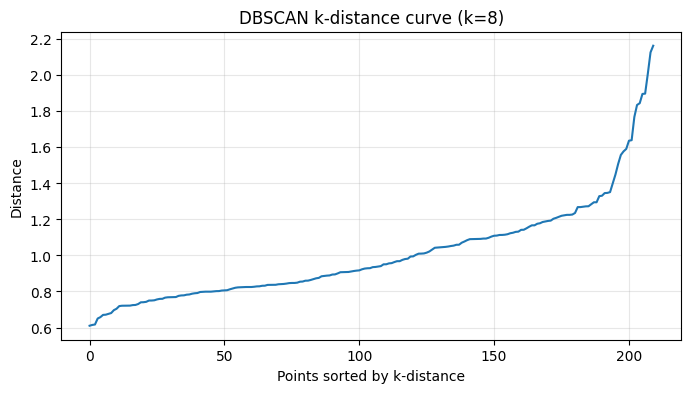

In [4]:
def pairwise_distances(X):
    # Euclidean distance matrix, computed with NumPy.
    sq = np.sum(X * X, axis=1)
    d2 = np.maximum(sq[:, None] + sq[None, :] - 2 * X @ X.T, 0.0)
    return np.sqrt(d2)

D = pairwise_distances(X)

def dbscan_from_distances(D, eps, min_samples):
    n = D.shape[0]
    labels = np.full(n, -99, dtype=int) 
    visited = np.zeros(n, dtype=bool)
    neighborhoods = [np.flatnonzero(D[i] <= eps) for i in range(n)]
    cluster_id = 0

    for i in range(n):
        if visited[i]:
            continue
        visited[i] = True
        neighbors = neighborhoods[i]
        if len(neighbors) < min_samples:
            labels[i] = -1
            continue

        labels[i] = cluster_id
        seeds = list(map(int, neighbors))
        seed_set = set(seeds)
        j = 0
        while j < len(seeds):
            point = seeds[j]
            if not visited[point]:
                visited[point] = True
                point_neighbors = neighborhoods[point]
                if len(point_neighbors) >= min_samples:
                    for q in point_neighbors:
                        q = int(q)
                        if q not in seed_set:
                            seeds.append(q)
                            seed_set.add(q)
            if labels[point] in (-99, -1):
                labels[point] = cluster_id
            j += 1
        cluster_id += 1
    labels[labels == -99] = -1
    return labels


min_samples_reference = 8
sorted_distances = np.sort(D, axis=1)
k_distances = np.sort(sorted_distances[:, min_samples_reference - 1])
plt.figure(figsize=(8, 4))
plt.plot(np.arange(len(k_distances)), k_distances)
plt.title(f"DBSCAN k-distance curve (k={min_samples_reference})")
plt.xlabel("Points sorted by k-distance")
plt.ylabel("Distance")
plt.grid(alpha=0.3)
plt.show()


In [5]:
def silhouette_score(X, labels):
    labels = np.asarray(labels)
    groups = [g for g in np.unique(labels) if g != -1]
    keep = labels != -1
    ids = np.flatnonzero(keep)
    if len(groups) < 2 or len(ids) <= len(groups):
        return np.nan
    Dsub = pairwise_distances(X[ids])
    lab = labels[ids]
    values = []
    for i in range(len(ids)):
        own = lab[i]
        same = np.flatnonzero(lab == own)
        same = same[same != i]
        a = Dsub[i, same].mean() if len(same) else 0.0
        b = min(Dsub[i, lab == other].mean() for other in groups if other != own)
        denom = max(a, b)
        values.append((b - a) / denom if denom else 0.0)
    return float(np.mean(values))

min_samples_reference = 8
sorted_distances = np.sort(D, axis=1)
k_distances = np.sort(sorted_distances[:, min_samples_reference - 1])

eps_candidates = np.unique(np.quantile(k_distances, np.linspace(0.05, 0.99, 100)))
min_samples_candidates = [4, 5, 6, 7, 8, 10, 12, 15]
trials = []

for eps in eps_candidates:
    for ms in min_samples_candidates:
        labels = dbscan_from_distances(D, float(eps), ms)
        cluster_count = len(set(labels) - {-1})
        noise_fraction = float(np.mean(labels == -1))
        sil = silhouette_score(X, labels) if cluster_count >= 2 else np.nan
        trials.append({
            "eps": float(eps),
            "min_samples": ms,
            "clusters": cluster_count,
            "noise_fraction": noise_fraction,
            "silhouette": sil
        })

trial_df = pd.DataFrame(trials)

# Prefer exactly 3 clusters, a reasonable noise fraction, and a stronger
# silhouette score. Silhouette is computed on non-noise points only.
exact3 = trial_df[
    (trial_df["clusters"] == 3) &
    (trial_df["noise_fraction"] <= 0.20) &
    (trial_df["min_samples"] >= 4)
]

if len(exact3):
    # Among solutions with <=20% noise, prioritize silhouette, then fewer noise points.
    best = exact3.sort_values(
        ["silhouette", "noise_fraction"],
        ascending=[False, True],
        na_position="last"
    ).iloc[0]
else:
    print("No setting met all preferred criteria; selecting the closest three-cluster result.")
    candidates = trial_df[(trial_df["clusters"] >= 2) & (trial_df["min_samples"] >= 4)].copy()
    if len(candidates) == 0:
        raise ValueError("DBSCAN could not form multiple clusters. Widen the eps grid.")
    candidates["cluster_penalty"] = (candidates["clusters"] - 3).abs()
    candidates = candidates.sort_values(
        ["cluster_penalty", "noise_fraction", "silhouette"],
        ascending=[True, True, False],
        na_position="last"
    )
    best = candidates.iloc[0]

best_eps = float(best["eps"])
best_min_samples = int(best["min_samples"])
dbscan_labels = dbscan_from_distances(D, best_eps, best_min_samples)

print(f"DBSCAN eps={best_eps:.4f}, min_samples={best_min_samples}")
print("Clusters (excluding noise):", len(set(dbscan_labels) - {-1}))
print("Noise points:", int(np.sum(dbscan_labels == -1)), "/", len(X),
      f"({np.mean(dbscan_labels == -1):.1%})")
print("Silhouette (excluding noise):", round(silhouette_score(X, dbscan_labels), 4))
display(exact3.sort_values(
    ["silhouette", "noise_fraction"], ascending=[False, True], na_position="last"
).head(10))


DBSCAN eps=0.8318, min_samples=4
Clusters (excluding noise): 3
Noise points: 39 / 210 (18.6%)
Silhouette (excluding noise): 0.3375


,eps,min_samples,clusters,noise_fraction,silhouette
216,0.831799,4,3,0.185714,0.337492
224,0.836552,4,3,0.180952,0.333530
338,0.907261,6,3,0.195238,0.251944
346,0.908330,6,3,0.195238,0.251944
330,0.899346,6,3,0.200000,0.250266
370,0.926137,6,3,0.180952,0.249164
354,0.913171,6,3,0.190476,0.247028
362,0.916839,6,3,0.190476,0.247028
378,0.929322,6,3,0.161905,0.242242
403,0.950940,7,3,0.171429,0.240349


Variance explained by first two PCs: 89.0%


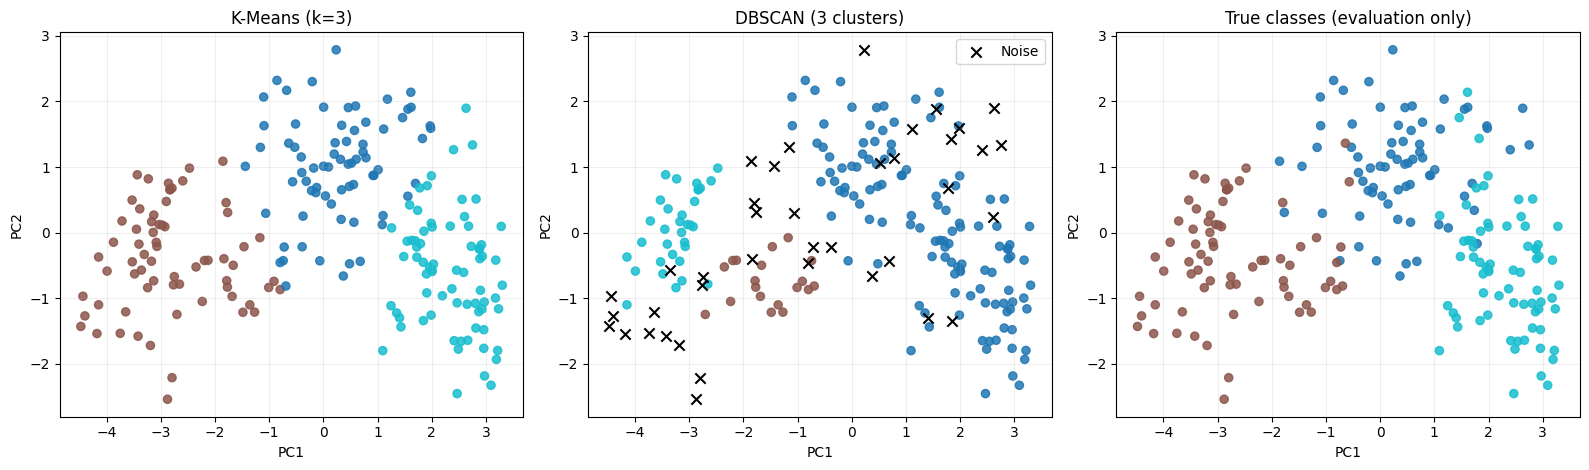

In [6]:
X_centered = X - X.mean(axis=0)
cov = np.cov(X_centered, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(cov)
order = np.argsort(eigenvalues)[::-1]
components = eigenvectors[:, order[:2]]
X_pca = X_centered @ components
variance_explained = eigenvalues[order[:2]].sum() / eigenvalues.sum()
print(f"Variance explained by first two PCs: {variance_explained:.1%}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="tab10", s=35, alpha=0.85)
axes[0].set_title("K-Means (k=3)")
axes[1].scatter(X_pca[dbscan_labels != -1, 0], X_pca[dbscan_labels != -1, 1],
                c=dbscan_labels[dbscan_labels != -1], cmap="tab10", s=35, alpha=0.85)
if np.any(dbscan_labels == -1):
    axes[1].scatter(X_pca[dbscan_labels == -1, 0], X_pca[dbscan_labels == -1, 1],
                    c="black", marker="x", s=55, label="Noise")
    axes[1].legend()
axes[1].set_title(f"DBSCAN ({len(set(dbscan_labels)-{-1})} clusters)")
true_codes, _ = pd.factorize(y_true)
axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=true_codes, cmap="tab10", s=35, alpha=0.85)
axes[2].set_title("True classes (evaluation only)")
for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [7]:
def contingency_matrix(y_true, y_pred):
    true_values, true_inv = np.unique(y_true, return_inverse=True)
    pred_values, pred_inv = np.unique(y_pred, return_inverse=True)
    table = np.zeros((len(true_values), len(pred_values)), dtype=int)
    np.add.at(table, (true_inv, pred_inv), 1)
    return table, true_values, pred_values

def adjusted_rand_index(y_true, y_pred):
    C, _, _ = contingency_matrix(y_true, y_pred)
    choose2 = lambda x: x * (x - 1) / 2
    sum_cells = choose2(C).sum()
    sum_rows = choose2(C.sum(axis=1)).sum()
    sum_cols = choose2(C.sum(axis=0)).sum()
    n = C.sum()
    total = choose2(n)
    expected = sum_rows * sum_cols / total if total else 0
    maximum = 0.5 * (sum_rows + sum_cols)
    return (sum_cells - expected) / (maximum - expected) if maximum != expected else 1.0

def normalized_mutual_info(y_true, y_pred):
    C, _, _ = contingency_matrix(y_true, y_pred)
    n = C.sum()
    P = C / n
    a = P.sum(axis=1)
    b = P.sum(axis=0)
    nz = P > 0
    rows, cols = np.where(nz)
    mi = np.sum(P[nz] * np.log(P[nz] / (a[rows] * b[cols])))
    ha = -np.sum(a[a > 0] * np.log(a[a > 0]))
    hb = -np.sum(b[b > 0] * np.log(b[b > 0]))
    return 2 * mi / (ha + hb) if ha + hb else 1.0

def evaluate(y, labels, name):
    return {"Algorithm": name,
            "Clusters (excluding noise)": len(set(labels) - {-1}),
            "Noise points": int(np.sum(labels == -1)),
            "ARI": adjusted_rand_index(y, labels),
            "NMI": normalized_mutual_info(y, labels)}

display(pd.DataFrame([
    evaluate(y_true, kmeans_labels, "K-Means (k=3)"),
    evaluate(y_true, dbscan_labels, f"DBSCAN (eps={best_eps:.3f})")
]).round(4))


,Algorithm,Clusters (excluding noise),Noise points,ARI,NMI
0,K-Means (k=3),3,0,0.7733,0.7279
1,DBSCAN (eps=0.832),3,39,0.3116,0.4154


In [8]:
print("True class vs K-Means cluster")
display(pd.crosstab(pd.Series(y_true, name="True class"),
                     pd.Series(kmeans_labels, name="K-Means cluster")))
print("True class vs DBSCAN cluster (-1 means noise)")
display(pd.crosstab(pd.Series(y_true, name="True class"),
                     pd.Series(dbscan_labels, name="DBSCAN cluster")))


True class vs K-Means cluster


K-Means cluster,0,1,2
True class,,,
1,62,2,6
2,5,65,0
3,4,0,66


True class vs DBSCAN cluster (-1 means noise)


DBSCAN cluster,-1,0,1,2
True class,,,,
1,17,52,1,0
2,17,2,18,33
3,5,65,0,0
